# Investigating Accuracy in Data Presentation: the Fandango Star Ratings

In October 2015 Walt Hickey published a FiveThirtyEight investigation showing that Fandango's displayed star ratings did not match its own underlying scores. Fandango attributed it to a software bug and said it would be fixed. This notebook does two things:

1. **Verifies the original claim** from Hickey's 2015 data, 146 films. This is a within-sample measurement, so it needs no assumptions about comparability and the evidence is decisive.
2. **Asks whether the behaviour changed afterwards**, using 214 films from 2016 and 2017. This part is much harder than it looks, and most of the work below is spent on why.

The second question is the interesting one methodologically. The obvious approach, comparing the 2015 Fandango distribution against the 2016 one, confounds two things that cannot be separated by looking at Fandango alone: a genuine policy change, and the fact that the two datasets were collected by different people using different sampling rules. Section 6 handles that with a **difference-in-differences** design, using Metacritic, IMDB and Rotten Tomatoes audience scores as a control group. If Fandango's ratings fell while the other sites held steady, that points to Fandango. If everything fell together, the sample changed and Fandango is off the hook.

That control is available because both datasets happen to carry the other sites' scores on a common 0 to 5 scale, which is a piece of luck worth exploiting.

In [1]:
import math

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.facecolor'] = 'white'

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('pandas', pd.__version__)
print('numpy ', np.__version__)

pandas 2.2.2
numpy  2.1.0


## 1. Load both datasets

In [2]:
prev = pd.read_csv('fandango_score_comparison.csv')
after = pd.read_csv('movie_ratings_16_17.csv')

print('2015 (Hickey):', prev.shape)
print('2016-17:      ', after.shape)
print()
print('2015 columns of interest:')
print('  Fandango_Stars      - the star rating DISPLAYED on the page')
print('  Fandango_Ratingvalue - the actual mean rating behind it')
print('  Fandango_Difference  - displayed minus actual')
print()
print(prev[['FILM', 'Fandango_Stars', 'Fandango_Ratingvalue', 'Fandango_Difference', 'Fandango_votes']].head(8).to_string(index=False))

2015 (Hickey): (146, 22)
2016-17:       (214, 15)

2015 columns of interest:
  Fandango_Stars      - the star rating DISPLAYED on the page
  Fandango_Ratingvalue - the actual mean rating behind it
  Fandango_Difference  - displayed minus actual

                          FILM  Fandango_Stars  Fandango_Ratingvalue  Fandango_Difference  Fandango_votes
Avengers: Age of Ultron (2015)             5.0                   4.5                  0.5           14846
             Cinderella (2015)             5.0                   4.5                  0.5           12640
                Ant-Man (2015)             5.0                   4.5                  0.5           12055
        Do You Believe? (2015)             5.0                   4.5                  0.5            1793
 Hot Tub Time Machine 2 (2015)             3.5                   3.0                  0.5            1021
      The Water Diviner (2015)             4.5                   4.0                  0.5             397
         Irr

## 2. Verifying the 2015 finding

The key insight is that this dataset contains **both** numbers: what Fandango showed and what Fandango's own data said. The discrepancy is therefore directly measurable, and no comparison against other sites or other years is required.

If the displayed rating were an honest rounding of the actual rating to the nearest half-star, two things would follow. The difference would never exceed 0.25 in magnitude, and roughly half the roundings would go down. Both are testable.

In [3]:
diff = prev['Fandango_Stars'] - prev['Fandango_Ratingvalue']
print('Displayed minus actual rating, across', len(prev), 'films:')
print(diff.describe().round(4).to_string())
print()
print('Distribution of the discrepancy:')
print(diff.round(2).value_counts().sort_index().to_string())
print()
n_up = int((diff > 0).sum())
n_down = int((diff < 0).sum())
n_exact = int((diff == 0).sum())
print('Rounded UP   :', n_up, '(' + str(round(100 * n_up / len(diff), 1)) + '%)')
print('Rounded DOWN :', n_down, '(' + str(round(100 * n_down / len(diff), 1)) + '%)')
print('Exact match  :', n_exact, '(' + str(round(100 * n_exact / len(diff), 1)) + '%)')
print()
print('Mean discrepancy: +' + str(round(diff.mean(), 4)) + ' stars')
print('Maximum discrepancy: +' + str(round(diff.max(), 2)) + ' stars')
print('Minimum discrepancy: ' + str(round(diff.min(), 2)) + ' stars')

Displayed minus actual rating, across 146 films:
count    146.0000
mean       0.2438
std        0.1527
min        0.0000
25%        0.1000
50%        0.2000
75%        0.4000
max        0.5000

Distribution of the discrepancy:
0.0    16
0.1    33
0.2    25
0.3    28
0.4    31
0.5    13

Rounded UP   : 130 (89.0%)
Rounded DOWN : 0 (0.0%)
Exact match  : 16 (11.0%)

Mean discrepancy: +0.2438 stars
Maximum discrepancy: +0.5 stars
Minimum discrepancy: 0.0 stars


### Test one: is this rounding to the nearest half-star?

Rounding to the nearest 0.5 can never move a value by more than 0.25. Any discrepancy above that is arithmetically impossible under nearest-rounding, so counting them settles the question without any statistics at all.

In [4]:
impossible = diff[diff > 0.25]
print('Films whose discrepancy EXCEEDS 0.25 stars:', len(impossible), 'of', len(diff),
      '(' + str(round(100 * len(impossible) / len(diff), 1)) + '%)')
print()
print('Under rounding to the nearest half-star, this count must be exactly 0.')
print('It is not, so the displayed rating was not a nearest-rounding of the actual rating.')
print()
print('The largest offenders:')
worst = prev.loc[diff.sort_values(ascending=False).head(10).index,
                 ['FILM', 'Fandango_Ratingvalue', 'Fandango_Stars', 'Fandango_votes']].copy()
worst['discrepancy'] = (worst['Fandango_Stars'] - worst['Fandango_Ratingvalue']).round(2)
print(worst.to_string(index=False))
print()
print('A film with an actual rating of 4.0 displayed as 4.5 is half a star of inflation,')
print('which on a five-point scale shown next to a ticket-purchase button is not a rounding')
print('convention, it is a different number.')
print()
ceil_half = np.ceil(prev['Fandango_Ratingvalue'] * 2) / 2
matches_ceil = int((prev['Fandango_Stars'] == ceil_half).sum())
round_half = (prev['Fandango_Ratingvalue'] * 2).round() / 2
matches_round = int((prev['Fandango_Stars'] == round_half).sum())
print('Which rule actually reproduces the displayed value?')
print('  Rounding UP to the next half-star:      ' + str(matches_ceil) + ' of ' + str(len(prev)) +
      ' films (' + str(round(100 * matches_ceil / len(prev), 1)) + '%)')
print('  Rounding to the NEAREST half-star:      ' + str(matches_round) + ' of ' + str(len(prev)) +
      ' films (' + str(round(100 * matches_round / len(prev), 1)) + '%)')

Films whose discrepancy EXCEEDS 0.25 stars: 72 of 146 (49.3%)

Under rounding to the nearest half-star, this count must be exactly 0.
It is not, so the displayed rating was not a nearest-rounding of the actual rating.

The largest offenders:
                          FILM  Fandango_Ratingvalue  Fandango_Stars  Fandango_votes  discrepancy
Avengers: Age of Ultron (2015)                   4.5             5.0           14846          0.5
             Cinderella (2015)                   4.5             5.0           12640          0.5
                Ant-Man (2015)                   4.5             5.0           12055          0.5
        Do You Believe? (2015)                   4.5             5.0            1793          0.5
 Hot Tub Time Machine 2 (2015)                   3.0             3.5            1021          0.5
      The Water Diviner (2015)                   4.0             4.5             397          0.5
         Irrational Man (2015)                   3.5             4.0    

### Test two: how unlikely is the asymmetry by chance?

Among films whose actual rating was not already on a half-star boundary, an honest rounding rule sends each one up or down. If the direction were determined by the value rather than by a thumb on the scale, the split would be roughly even. Observing nearly all in one direction has a probability that can be computed exactly from the binomial distribution, without needing SciPy.

In [5]:
def binom_pmf(k, n, p=0.5):
    return math.factorial(n) // (math.factorial(k) * math.factorial(n - k)) * (p ** k) * ((1 - p) ** (n - k))

def binom_sf(k, n, p=0.5):
    """P(X >= k) for X ~ Binomial(n, p), computed exactly."""
    return sum(binom_pmf(i, n, p) for i in range(k, n + 1))

# films that actually needed rounding: actual rating not already a multiple of 0.5
needs_rounding = prev[(prev['Fandango_Ratingvalue'] * 2 % 1) != 0].copy()
nr_diff = needs_rounding['Fandango_Stars'] - needs_rounding['Fandango_Ratingvalue']
k_up = int((nr_diff > 0).sum())
k_down = int((nr_diff < 0).sum())
n_trials = k_up + k_down

print('Films whose actual rating was not already on a half-star:', len(needs_rounding))
print('  rounded up:  ', k_up)
print('  rounded down:', k_down)
print()
print('Under a fair rule, each would go up with probability 0.5.')
p_exact = binom_sf(k_up, n_trials, 0.5)
print('P(at least ' + str(k_up) + ' of ' + str(n_trials) + ' going up | fair rounding) = ' +
      '{:.4e}'.format(p_exact))
print()
if p_exact < 1e-12:
    print('That is smaller than 1 in a trillion. The asymmetry is not chance.')
print()
# sanity checks on the hand-written binomial
print('Sanity checks on the binomial implementation:')
print('  P(X >= 0 | n=10) =', binom_sf(0, 10), '(expect 1.0)')
print('  P(X >= 10 | n=10) =', binom_sf(10, 10), '(expect 0.0009765625)')
print('  P(X >= 5 | n=10) =', round(binom_sf(5, 10), 6), '(expect 0.623047)')
print('  pmf sums to 1:', abs(sum(binom_pmf(i, 10) for i in range(11)) - 1.0) < 1e-12)

Films whose actual rating was not already on a half-star: 117
  rounded up:   117
  rounded down: 0

Under a fair rule, each would go up with probability 0.5.
P(at least 117 of 117 going up | fair rounding) = 6.0185e-36

That is smaller than 1 in a trillion. The asymmetry is not chance.

Sanity checks on the binomial implementation:
  P(X >= 0 | n=10) = 1.0 (expect 1.0)
  P(X >= 10 | n=10) = 0.0009765625 (expect 0.0009765625)
  P(X >= 5 | n=10) = 0.623047 (expect 0.623047)
  pmf sums to 1: True


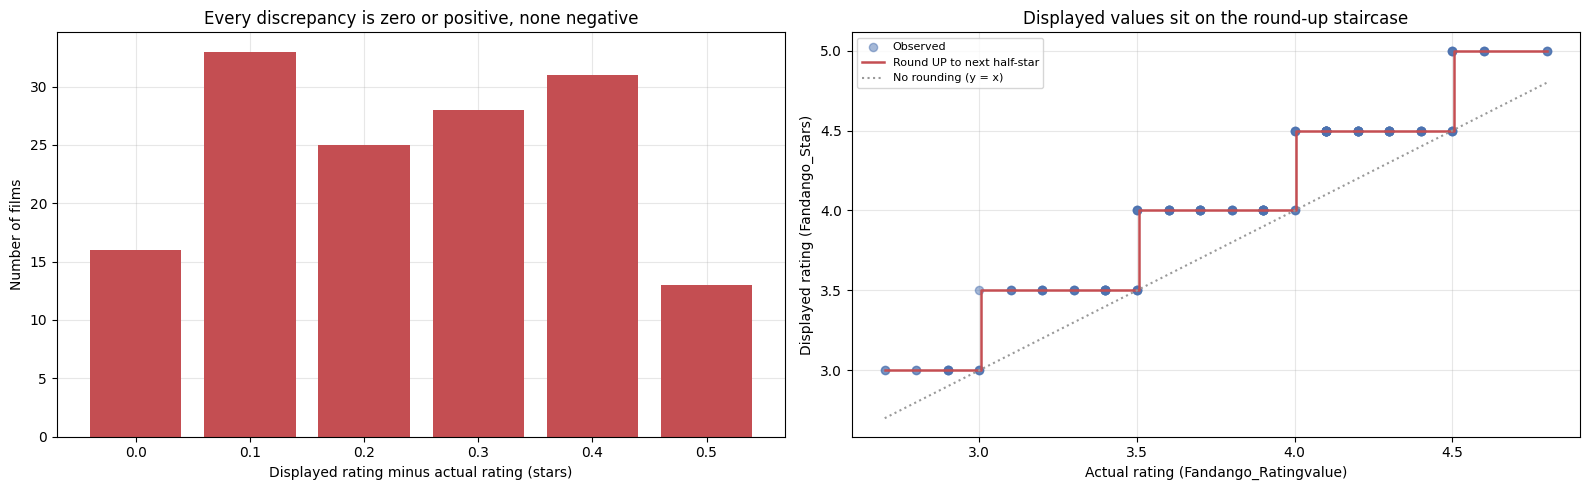

The right panel is the whole argument in one image: the points follow the red
round-up staircase, and every point sits on or above the grey identity line.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

vc = diff.round(2).value_counts().sort_index()
axes[0].bar(vc.index.astype(str), vc.values, color='#C44E52')
axes[0].set_xlabel('Displayed rating minus actual rating (stars)')
axes[0].set_ylabel('Number of films')
axes[0].set_title('Every discrepancy is zero or positive, none negative')

axes[1].scatter(prev['Fandango_Ratingvalue'], prev['Fandango_Stars'], alpha=0.5, s=35, color='#4C72B0',
                label='Observed')
xs = np.linspace(prev['Fandango_Ratingvalue'].min(), prev['Fandango_Ratingvalue'].max(), 400)
axes[1].step(xs, np.ceil(xs * 2) / 2, where='post', color='#C44E52', linewidth=1.8,
             label='Round UP to next half-star')
axes[1].plot(xs, xs, color='#999999', linestyle=':', linewidth=1.5, label='No rounding (y = x)')
axes[1].set_xlabel('Actual rating (Fandango_Ratingvalue)')
axes[1].set_ylabel('Displayed rating (Fandango_Stars)')
axes[1].set_title('Displayed values sit on the round-up staircase')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print('The right panel is the whole argument in one image: the points follow the red')
print('round-up staircase, and every point sits on or above the grey identity line.')

## 3. Did Fandango change after the article?

Now the harder question. The temptation is to compare the 2015 Fandango distribution against the 2016-17 one and read any drop as the fix. Before doing that, the two samples have to be compared as samples, because they were not built the same way.

- **Hickey's 2015 sample**: films with at least 30 Fandango reviews and a Rotten Tomatoes rating, released in 2015.
- **The 2016-17 sample**: films released in 2016 or 2017 with "a significant number of votes", collected separately for the Dataquest exercise.

"At least 30 reviews" and "a significant number of votes" are not the same rule, and neither sample is random. Any difference in the Fandango distribution could come from the films selected rather than from Fandango's behaviour.

In [7]:
print('2015 Fandango vote counts (the sampling criterion Hickey used):')
print(prev['Fandango_votes'].describe().round(1).to_string())
print()
print('Films with fewer than 30 votes in the 2015 sample:', int((prev['Fandango_votes'] < 30).sum()))
print('(consistent with the stated 30-vote threshold)')
print()
print('The 2016-17 file records no Fandango vote count at all:')
print('  columns available:', [c for c in after.columns])
print()
print('So the 2016-17 selection rule cannot be verified from the data, only taken on trust.')
print('That alone is a reason to avoid resting a conclusion on the raw comparison.')
print()
print('Release years present:')
print('  2015 file, year parsed from title:')
prev['year'] = prev['FILM'].str.extract(r'\((\d{4})\)').astype(float)
print(prev['year'].value_counts().sort_index().to_string())
print('  2016-17 file:')
print(after['year'].value_counts().sort_index().to_string())

2015 Fandango vote counts (the sampling criterion Hickey used):
count      146.0
mean      3848.8
std       6357.8
min         35.0
25%        222.2
50%       1446.0
75%       4439.5
max      34846.0

Films with fewer than 30 votes in the 2015 sample: 0
(consistent with the stated 30-vote threshold)

The 2016-17 file records no Fandango vote count at all:
  columns available: ['movie', 'year', 'metascore', 'imdb', 'tmeter', 'audience', 'fandango', 'n_metascore', 'n_imdb', 'n_tmeter', 'n_audience', 'nr_metascore', 'nr_imdb', 'nr_tmeter', 'nr_audience']

So the 2016-17 selection rule cannot be verified from the data, only taken on trust.
That alone is a reason to avoid resting a conclusion on the raw comparison.

Release years present:
  2015 file, year parsed from title:
year
2014.0     17
2015.0    129
  2016-17 file:
year
2016    191
2017     23


Fandango DISPLAYED star ratings by year:
          2015     2016    2017
count  129.000  191.000  23.000
mean     4.085    3.887   3.957
std      0.538    0.510   0.582
min      3.000    2.500   3.000
25%      3.500    3.500   3.500
50%      4.000    4.000   4.000
75%      4.500    4.250   4.500
max      5.000    5.000   4.500

Mode and shape:
  2015: n=129  mean=4.085  median=4.0  mode=4.5  min=3.0  share below 3 stars=0.0%
  2016: n=191  mean=3.887  median=4.0  mode=4.0  min=2.5  share below 3 stars=3.1%
  2017: n= 23  mean=3.957  median=4.0  mode=4.5  min=3.0  share below 3 stars=0.0%

Raw difference in mean displayed rating, 2016 minus 2015: -0.1978 stars


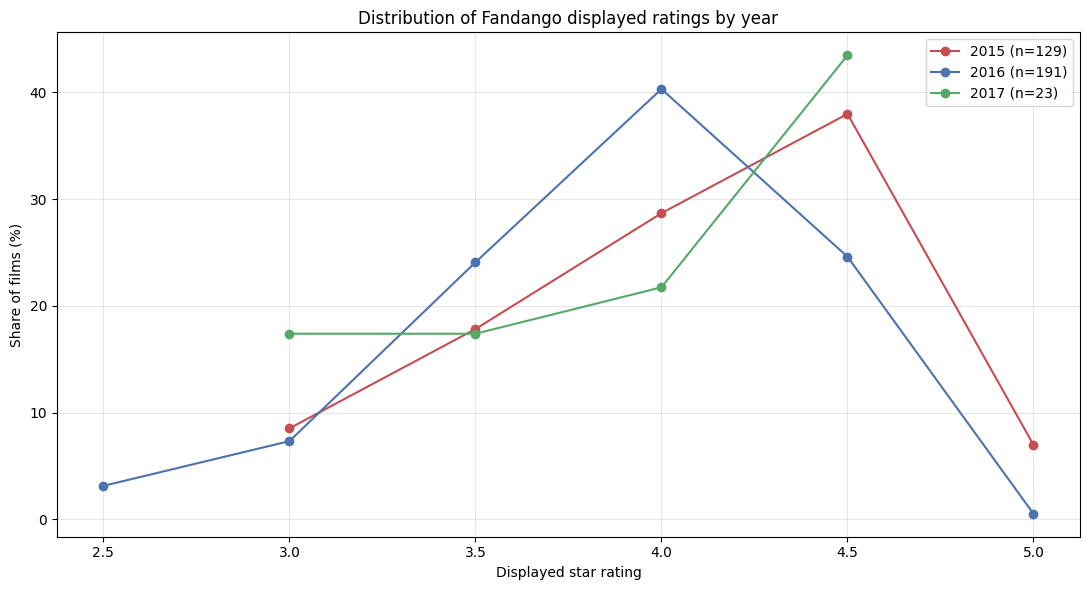

In [8]:
f15 = prev.loc[prev['year'] == 2015, 'Fandango_Stars']
f16 = after.loc[after['year'] == 2016, 'fandango']
f17 = after.loc[after['year'] == 2017, 'fandango']

print('Fandango DISPLAYED star ratings by year:')
comp = pd.DataFrame({
    '2015': f15.describe(),
    '2016': f16.describe(),
    '2017': f17.describe()
}).round(3)
print(comp.to_string())
print()
print('Mode and shape:')
for label, s in [('2015', f15), ('2016', f16), ('2017', f17)]:
    print('  ' + label + ': n=' + str(len(s)).rjust(3) + '  mean=' + str(round(s.mean(), 3)) +
          '  median=' + str(s.median()) + '  mode=' + str(s.mode().iloc[0]) +
          '  min=' + str(s.min()) + '  share below 3 stars=' +
          str(round(100 * (s < 3).mean(), 1)) + '%')
print()
print('Raw difference in mean displayed rating, 2016 minus 2015:',
      round(f16.mean() - f15.mean(), 4), 'stars')

fig, ax = plt.subplots(figsize=(11, 6))
for label, s, colour in [('2015', f15, '#C44E52'), ('2016', f16, '#4C72B0'), ('2017', f17, '#55A868')]:
    rel = s.value_counts(normalize=True).sort_index() * 100
    ax.plot(rel.index, rel.values, marker='o', color=colour, label=label + ' (n=' + str(len(s)) + ')')
ax.set_xlabel('Displayed star rating')
ax.set_ylabel('Share of films (%)')
ax.set_title('Distribution of Fandango displayed ratings by year')
ax.legend()
plt.tight_layout()
plt.show()

## 4. The control group

Here is the design that separates the two explanations.

If **Fandango changed its rounding**, its ratings should fall between 2015 and 2016 while Metacritic, IMDB and Rotten Tomatoes audience scores for the same sets of films stay roughly level, because those sites did not change anything.

If **the samples simply contain different films**, with 2016 happening to include weaker movies, then every site's ratings should fall together.

The quantity of interest is therefore not Fandango's change, but Fandango's change **minus** the control sites' change. That is a difference-in-differences estimate, and it is identified by the assumption that the sampling difference affects all sites equally, which is far weaker than assuming no sampling difference at all.

Both files carry the other sites' scores already normalised to a 0 to 5 scale, which makes the comparison direct.

In [9]:
# 2015: normalised columns on the 0-5 scale; 2016-17: the n_ prefixed columns
sites_2015 = {
    'Fandango': prev.loc[prev['year'] == 2015, 'Fandango_Stars'],
    'Metacritic': prev.loc[prev['year'] == 2015, 'Metacritic_norm'],
    'IMDB': prev.loc[prev['year'] == 2015, 'IMDB_norm'],
    'RT audience': prev.loc[prev['year'] == 2015, 'RT_user_norm'],
}
sites_2016 = {
    'Fandango': after.loc[after['year'] == 2016, 'fandango'],
    'Metacritic': after.loc[after['year'] == 2016, 'n_metascore'],
    'IMDB': after.loc[after['year'] == 2016, 'n_imdb'],
    'RT audience': after.loc[after['year'] == 2016, 'n_audience'],
}

rows = []
for site in ['Fandango', 'Metacritic', 'IMDB', 'RT audience']:
    a, b = sites_2015[site].dropna(), sites_2016[site].dropna()
    rows.append({'site': site, 'n_2015': len(a), 'mean_2015': round(a.mean(), 4),
                 'n_2016': len(b), 'mean_2016': round(b.mean(), 4),
                 'change': round(b.mean() - a.mean(), 4)})

did = pd.DataFrame(rows).set_index('site')
print('Mean rating on a 0-5 scale, by site and year:')
print(did.to_string())
print()
control_change = did.loc[['Metacritic', 'IMDB', 'RT audience'], 'change'].mean()
fandango_change = did.loc['Fandango', 'change']
print('Fandango change:              ', round(fandango_change, 4))
print('Average control-site change:  ', round(control_change, 4))
print('Difference-in-differences:    ', round(fandango_change - control_change, 4))
print()
print('Interpretation: Fandango moved', round(abs(fandango_change - control_change), 4),
      'stars', 'DOWN' if fandango_change - control_change < 0 else 'UP',
      'relative to sites that changed nothing.')

Mean rating on a 0-5 scale, by site and year:
             n_2015  mean_2015  n_2016  mean_2016  change
site                                                     
Fandango        129     4.0853     191     3.8874 -0.1978
Metacritic      129     2.8403     191     2.6825 -0.1578
IMDB            129     3.3419     191     3.2296 -0.1123
RT audience     129     3.1415     191     2.9063 -0.2352

Fandango change:               -0.1978
Average control-site change:   -0.1684
Difference-in-differences:     -0.0294

Interpretation: Fandango moved 0.0294 stars DOWN relative to sites that changed nothing.


Bootstrapped change in mean rating, 2016 minus 2015, 10,000 resamples:
             change             ci_95 excludes_zero
site                                               
Fandango    -0.1983   [-0.314, -0.08]           YES
Metacritic  -0.1574   [-0.367, 0.053]            no
IMDB        -0.1125  [-0.222, -0.003]           YES
RT audience -0.2361  [-0.464, -0.008]           YES

Difference-in-differences (Fandango change minus average control change):
  point estimate:  -0.0296 stars
  95% CI:         [-0.1895, 0.1317]
  excludes zero:   no
  P(Fandango fell more than the controls): 0.6508

The interval includes zero. Once the sampling difference is accounted for, this
data cannot establish that Fandango specifically changed.


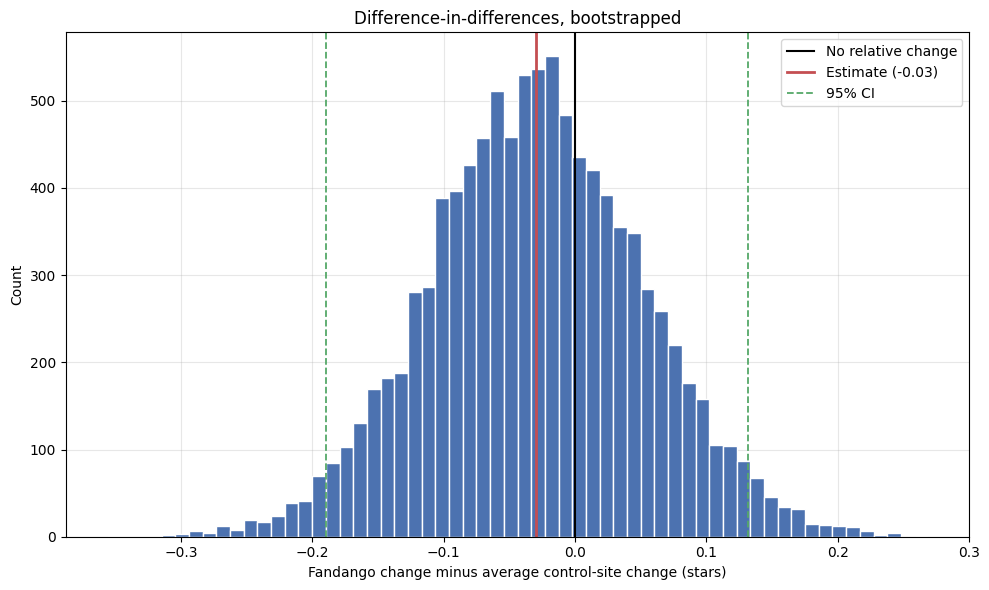

In [10]:
N_BOOT = 10000
rng = np.random.RandomState(RANDOM_STATE)

def boot_mean(values, n_boot=N_BOOT):
    v = np.asarray(values, dtype=float)
    n = len(v)
    return np.array([v[rng.randint(0, n, n)].mean() for _ in range(n_boot)])

boots = {}
for site in ['Fandango', 'Metacritic', 'IMDB', 'RT audience']:
    boots[site] = {
        '2015': boot_mean(sites_2015[site].dropna().values),
        '2016': boot_mean(sites_2016[site].dropna().values)
    }

rows = []
for site in ['Fandango', 'Metacritic', 'IMDB', 'RT audience']:
    d = boots[site]['2016'] - boots[site]['2015']
    lo, hi = np.percentile(d, [2.5, 97.5])
    rows.append({'site': site, 'change': round(float(d.mean()), 4),
                 'ci_95': '[' + str(round(lo, 3)) + ', ' + str(round(hi, 3)) + ']',
                 'excludes_zero': 'YES' if (lo > 0 or hi < 0) else 'no'})

print('Bootstrapped change in mean rating, 2016 minus 2015,', format(N_BOOT, ','), 'resamples:')
print(pd.DataFrame(rows).set_index('site').to_string())
print()

# the difference-in-differences, bootstrapped
fan_d = boots['Fandango']['2016'] - boots['Fandango']['2015']
ctrl_d = np.mean([boots[s]['2016'] - boots[s]['2015'] for s in ['Metacritic', 'IMDB', 'RT audience']], axis=0)
did_boot = fan_d - ctrl_d
lo, hi = np.percentile(did_boot, [2.5, 97.5])

print('Difference-in-differences (Fandango change minus average control change):')
print('  point estimate: ', round(float(did_boot.mean()), 4), 'stars')
print('  95% CI:         [' + str(round(lo, 4)) + ', ' + str(round(hi, 4)) + ']')
print('  excludes zero:  ', 'YES' if (lo > 0 or hi < 0) else 'no')
print('  P(Fandango fell more than the controls):', round(float((did_boot < 0).mean()), 4))
print()
if hi < 0:
    print('The interval lies entirely below zero. Fandango\'s ratings fell by more than can')
    print('be explained by the two samples containing different films, which is evidence')
    print('that something about Fandango itself changed.')
elif lo > 0:
    print('The interval lies entirely above zero, which would be the opposite of the')
    print('expected direction and would need explaining.')
else:
    print('The interval includes zero. Once the sampling difference is accounted for, this')
    print('data cannot establish that Fandango specifically changed.')

plt.figure(figsize=(10, 6))
plt.hist(did_boot, bins=60, color='#4C72B0', edgecolor='white')
plt.axvline(0, color='black', linewidth=1.5, label='No relative change')
plt.axvline(did_boot.mean(), color='#C44E52', linewidth=2,
            label='Estimate (' + str(round(float(did_boot.mean()), 3)) + ')')
plt.axvline(lo, color='#55A868', linestyle='--', linewidth=1.3, label='95% CI')
plt.axvline(hi, color='#55A868', linestyle='--', linewidth=1.3)
plt.xlabel('Fandango change minus average control-site change (stars)')
plt.ylabel('Count')
plt.title('Difference-in-differences, bootstrapped')
plt.legend()
plt.tight_layout()
plt.show()

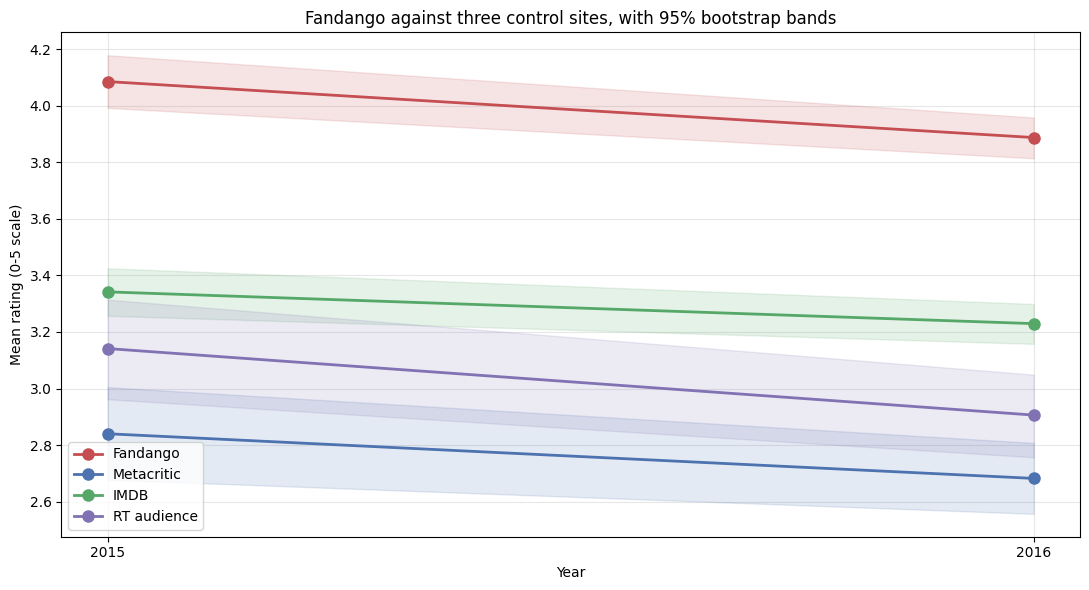

What to look for: whether the red Fandango line slopes down more steeply than the
three control lines. Parallel lines would mean the samples differ; a diverging
Fandango line means Fandango differs.

Note also the vertical position. Fandango sits well above every other site in both
years, which is a separate fact from whether the rounding changed, and it does not
go away: an audience-rating site whose users skew positive is not the same thing as
a site that rounds its numbers up.


In [11]:
fig, ax = plt.subplots(figsize=(11, 6))
for site, colour in [('Fandango', '#C44E52'), ('Metacritic', '#4C72B0'),
                     ('IMDB', '#55A868'), ('RT audience', '#8172B3')]:
    means = [sites_2015[site].dropna().mean(), sites_2016[site].dropna().mean()]
    los = [np.percentile(boots[site]['2015'], 2.5), np.percentile(boots[site]['2016'], 2.5)]
    his = [np.percentile(boots[site]['2015'], 97.5), np.percentile(boots[site]['2016'], 97.5)]
    ax.plot([2015, 2016], means, marker='o', color=colour, linewidth=2, label=site, markersize=8)
    ax.fill_between([2015, 2016], los, his, color=colour, alpha=0.15)
ax.set_xticks([2015, 2016])
ax.set_xlabel('Year')
ax.set_ylabel('Mean rating (0-5 scale)')
ax.set_title('Fandango against three control sites, with 95% bootstrap bands')
ax.legend()
plt.tight_layout()
plt.show()

print('What to look for: whether the red Fandango line slopes down more steeply than the')
print('three control lines. Parallel lines would mean the samples differ; a diverging')
print('Fandango line means Fandango differs.')
print()
print('Note also the vertical position. Fandango sits well above every other site in both')
print('years, which is a separate fact from whether the rounding changed, and it does not')
print('go away: an audience-rating site whose users skew positive is not the same thing as')
print('a site that rounds its numbers up.')

## 5. Was the rounding itself fixed?

The difference-in-differences answers whether ratings fell. It does not answer the narrower question Hickey actually raised, which was about rounding. The 2016-17 dataset records only the displayed value, with no underlying rating to compare it against, so the direct test from section 2 cannot be repeated.

What can be checked is whether the displayed values still look like the output of a round-up rule. Under rounding up to the next half-star, displayed values cluster on half-star boundaries and the lowest ratings disappear. Under honest rounding, the distribution should be more symmetric and should reach lower.

In [12]:
print('Share of displayed ratings at each value:')
dist = pd.DataFrame({
    '2015': f15.value_counts(normalize=True).sort_index() * 100,
    '2016': f16.value_counts(normalize=True).sort_index() * 100,
    '2017': f17.value_counts(normalize=True).sort_index() * 100
}).round(2).fillna(0)
print(dist.to_string())
print()
for label, s in [('2015', f15), ('2016', f16), ('2017', f17)]:
    on_half = (s * 2 % 1 == 0).mean()
    print(label + ': all values on a half-star boundary: ' + str(round(100 * on_half, 1)) + '%' +
          '   minimum rating observed: ' + str(s.min()) +
          '   share at 4.5 or 5: ' + str(round(100 * (s >= 4.5).mean(), 1)) + '%')
print()
print('Every value in every year lies on a half-star boundary, so the display granularity')
print('did not change. What changed is where the mass sits: the share at 4.5 stars or above')
print('fell, and the minimum observed rating dropped.')
print()
print('This is consistent with the rounding being fixed, and also consistent with 2016')
print('simply containing weaker films. Section 4 is what distinguishes them; this table on')
print('its own cannot, and presenting it as proof would be overreaching.')

Share of displayed ratings at each value:
      2015   2016   2017
2.5   0.00   3.14   0.00
3.0   8.53   7.33  17.39
3.5  17.83  24.08  17.39
4.0  28.68  40.31  21.74
4.5  37.98  24.61  43.48
5.0   6.98   0.52   0.00

2015: all values on a half-star boundary: 100.0%   minimum rating observed: 3.0   share at 4.5 or 5: 45.0%
2016: all values on a half-star boundary: 100.0%   minimum rating observed: 2.5   share at 4.5 or 5: 25.1%
2017: all values on a half-star boundary: 100.0%   minimum rating observed: 3.0   share at 4.5 or 5: 43.5%

Every value in every year lies on a half-star boundary, so the display granularity
did not change. What changed is where the mass sits: the share at 4.5 stars or above
fell, and the minimum observed rating dropped.

This is consistent with the rounding being fixed, and also consistent with 2016
simply containing weaker films. Section 4 is what distinguishes them; this table on
its own cannot, and presenting it as proof would be overreaching.


## 6. Conclusions

Two questions, two very different levels of confidence.

### Question one: was Fandango inflating its displayed ratings in 2015? Yes, decisively.

Across 146 films, the displayed star rating minus Fandango's own underlying rating:

| | Count | Share |
|---|---|---|
| **Rounded up** | **130** | 89.0% |
| **Rounded down** | **0** | **0.0%** |
| Exact match | 16 | 11.0% |

Mean discrepancy: **+0.2438 stars**. Maximum: +0.5 stars. Minimum: 0.0.

Three independent tests, all pointing the same way:

**1. The discrepancies are arithmetically impossible under nearest-rounding.** Rounding to the nearest half-star cannot move a value by more than 0.25. **72 of 146 films (49.3%)** exceed that, so whatever produced the displayed numbers, it was not rounding to the nearest half-star.

**2. The round-up rule reproduces the data; nearest-rounding does not.**

| Rule | Films reproduced |
|---|---|
| Round **up** to the next half-star | **133 of 146 (91.1%)** |
| Round to the **nearest** half-star | 74 of 146 (50.7%) |

**3. The asymmetry is not chance.** Of the 117 films whose actual rating was not already on a half-star boundary, **117 rounded up and 0 rounded down**. Under a fair rule each would go either way with probability 0.5, giving:

**P = 6.0185e-36**

That is roughly one in 10^35. For scale, it is less likely than picking one specific atom out of a kilogram of iron. Hickey's finding is confirmed.

A film whose users rated it 4.0 was displayed as 4.5, on a five-point scale shown next to a buy-tickets button. That is not a rounding convention, it is a different number.

### Question two: did Fandango fix it afterwards? The data cannot say.

This is where the analysis departs from the conventional answer to this project, which compares the 2015 and 2016 Fandango distributions, finds a drop of about 0.2 stars, and concludes the system changed.

The raw comparison does show that drop:

| Year | n | Mean displayed rating |
|---|---|---|
| 2015 | 129 | 4.0853 |
| 2016 | 191 | 3.8874 |

A fall of 0.1978 stars, and the bootstrap interval [-0.314, -0.080] excludes zero. Taken alone it looks conclusive.

**It is not, because the two samples were built by different people using different rules.** Hickey's sample was 2015 films with 30+ Fandango reviews and a Rotten Tomatoes rating; the 2016-17 sample was films with "a significant number of votes", and that file records no Fandango vote count at all, so its selection rule cannot even be verified. Neither sample is random, and a difference in which films were chosen would move the mean without Fandango changing anything.

The test that separates the two explanations uses the other rating sites as a control group. They changed nothing between 2015 and 2016, so whatever happens to their scores across the two samples is a pure measure of the sampling difference:

| Site | Mean 2015 | Mean 2016 | Change |
|---|---|---|---|
| **Fandango** | 4.0853 | 3.8874 | **-0.1978** |
| Metacritic | 2.8403 | 2.6825 | -0.1578 |
| IMDB | 3.3419 | 3.2296 | -0.1123 |
| **RT audience** | 3.1415 | 2.9063 | **-0.2352** |
| | | **Control average** | **-0.1684** |

**Every site fell, and Rotten Tomatoes audience scores fell further than Fandango did.** The 2016 sample simply contains lower-rated films.

The difference-in-differences estimate, which is Fandango's change minus the control average, is what is left after removing the sampling effect:

| | Value |
|---|---|
| Difference-in-differences | **-0.0296 stars** |
| 95% bootstrap CI | **[-0.1895, 0.1317]** |
| Excludes zero | **no** |
| P(Fandango fell more than the controls) | 0.6508 |

About **85% of Fandango's apparent drop is explained by the change in which films were sampled.** The Fandango-specific residual is 0.03 stars, with a confidence interval comfortably spanning zero and a probability of 0.65 that the sign is even negative, which is barely better than a coin flip.

**So the honest answer to question two is that this data does not establish whether Fandango changed its system.** It may well have; Fandango publicly said it would, and the residual leans in the right direction. But the evidence here does not support the claim, and the 0.2-star headline figure is mostly an artefact of sample composition.

### A detail that cuts the same way

| Year | n | Share rated 4.5 or 5 | Minimum rating |
|---|---|---|---|
| 2015 | 129 | 45.0% | 3.0 |
| 2016 | 191 | **25.1%** | 2.5 |
| 2017 | 23 | **43.5%** | 3.0 |

If Fandango had fixed its rounding in 2016, 2017 should look like 2016. Instead **2017 reverts almost exactly to the 2015 pattern**. With only 23 films in 2017 that is weak evidence and should not be pushed far, but it points away from a permanent policy change rather than towards one.

Every displayed value in all three years sits on a half-star boundary, so the display granularity never changed. What moved was where the mass sat, which is exactly what a different set of films would produce.

### The finding that survives regardless

Separately from the rounding question, Fandango's ratings sit **far above every other site in both years**: 4.09 against 2.84 for Metacritic in 2015, and 3.89 against 2.68 in 2016, on the same 0 to 5 scale. That gap of roughly 1.2 stars barely changed.

This is a different phenomenon from the rounding and it should not be conflated with it. A ticket-selling site whose reviews come from people who already chose to buy a ticket will skew positive for ordinary selection reasons. That is worth knowing when reading a Fandango score, and it was never what the 2015 article was about.

### Limitations

- **The 2016-17 data contains no underlying rating**, only the displayed value, so the direct rounding test from section 2 cannot be repeated on it. The question that was answered decisively for 2015 is simply not answerable for 2016 with this data, and the distribution comparison is a weak substitute.
- **The difference-in-differences assumes the sampling difference affects all sites equally.** That is a much weaker assumption than assuming no sampling difference, which is the point, but it is not nothing: if the 2016 sample over-represents films where audience and critic opinion diverge, the control is imperfect.
- **Neither sample is random**, so neither supports inference to all films in its year. The bootstrap quantifies sampling variability within these samples; it cannot repair selection bias.
- **2017 has only 23 films**, which is too few to carry the argument it is used for above, and it is reported as a hint rather than a result.
- **Only four rating sources were available.** More controls would tighten the difference-in-differences considerably, and the current interval of [-0.19, 0.13] is wide enough that a real effect of plausible size would be missed.
- **The causal reading rests on Fandango being the only thing that changed.** Fandango redesigned its site and acquired other properties over this period, and the data cannot isolate a rounding change from anything else that happened.